# Taller de Aprendizaje No Supervisado
## Parte 1: Dataset de Setas (variables categóricas)

### Mushroom Dataset

Podéis obtener el conjunto de datos en el siguiente enlace:

[Mushroom Dataset](https://www.kaggle.com/uciml/mushroom-classification)

Como podréis comprobar, hay **muchas variables, todas categóricas**, por lo que las exploraciones con *scatterplot* no nos serán útiles como en otros casos.

La variable a predecir es `class` (`e` = comestible / *edible*, `p` = venenosa / *poisonous*) y es **binaria**.

> En este taller usaremos las etiquetas **solo para validar** lo que descubre el clustering. La idea del aprendizaje no supervisado es encontrar estructura *sin* mirar la etiqueta.

### Algoritmos que cubriremos

**Reducción de dimensionalidad:** PCA (lineal) y t-SNE (no lineal).

**Clustering:** K-Means, Clustering Jerárquico (Aglomerativo), Gaussian Mixture Models (GMM) y DBSCAN.

**Evaluación:** método del codo, *silhouette*, Davies-Bouldin, Calinski-Harabasz y (como tenemos etiqueta) Adjusted Rand Index y NMI.

**Detección de anomalías:** Isolation Forest.

In [2]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook, justo debajo de la celda que los crea.
import warnings
warnings.filterwarnings("ignore")  # oculta avisos (FutureWarning, etc.) para que la salida quede limpia en clase

# Tablas y cálculo numérico
import pandas as pd      # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np       # arrays y operaciones matemáticas rápidas
# Gráficos
import seaborn as sns            # gráficos estadísticos bonitos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos (títulos, ejes, plt.show())
# Preparación de datos y reducción de dimensiones
from sklearn.model_selection import train_test_split  # separa datos en entrenamiento y examen
from sklearn.decomposition import PCA                 # reducción de dimensiones lineal
# Algoritmos de clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.manifold import TSNE                     # reducción de dimensiones no lineal (solo para visualizar)
from sklearn.mixture import GaussianMixture          # GMM: clusters como "nubes" probabilísticas
# Modelos supervisado y de anomalías
from sklearn.ensemble import RandomForestClassifier, IsolationForest
# Métricas para evaluar los clusters (3 internas + 2 que usan la etiqueta: ARI y NMI)
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
# Para dibujar el dendrograma
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid')  # estilo visual de todos los gráficos: fondo blanco con rejilla
RANDOM_STATE = 42 

### Leer conjunto de datos y primer vistazo

In [3]:
# Leer el csv (esta en 'data/mushrooms.csv') y sacar por pantalla las cinco primeras filas.
df = pd.read_csv('data/mushrooms.csv')
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### Exploración de datos

In [4]:
# Descripcion del conjunto de datos, estandar.
df.describe()
df.describe().T

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


In [5]:
# Informacion sobre el tipo de datos de cada feature.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

#### Calcular el número de nulos de cada feature

In [6]:
# Igual que otras veces, una linea: contar los nulos por variable.
df.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

#### Buscar valores extraños. Para ello, ver los valores únicos en cada feature

In [7]:
# Obtener un nuevo dataframe: en una columna las features (feature)
# y en la otra el numero de valores unicos asociados (n_values).
n_values = df.nunique()
n_values = n_values.reset_index()
n_values.columns = ['feature', 'n_values']
n_values.sort_values('n_values')

,feature,n_values
16,veil-type,1
0,class,2
4,bruises,2
6,gill-attachment,2
7,gill-spacing,2
8,gill-size,2
10,stalk-shape,2
18,ring-number,3
2,cap-surface,4
17,veil-color,4


In [8]:
(df == '?').sum() 

class                          0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64

Observad dos cosas:
- `veil-type` tiene **un único valor** → no aporta información.
- `stalk-root` contiene el valor `'?'`, que en realidad es un **valor desconocido (nulo encubierto)**.

#### Tratar aquellos valores que entendamos que sean nulos

In [9]:
# Imputaciones. Podeis quitar esos puntos (fila entera), imputar con la moda
# o dejar ese valor como una posibilidad mas. Aqui imputamos '?' con la moda.
moda = df['stalk-root'].mode()[0]
df['stalk-root'] = df['stalk-root'].replace('?', 'b')
df['stalk-root'].value_counts()

stalk-root
b    6256
e    1120
c     556
r     192
Name: count, dtype: int64

#### ¿Todas las features aportan información? Si alguna no aporta, eliminadla

In [10]:
# Dejar por el camino las features con un solo valor (no aportan nada).
cols_constantes = df.columns[df.nunique() == 1]
df = df.drop(columns=cols_constantes)

print(cols_constantes)
df.shape

Index(['veil-type'], dtype='object')


(8124, 22)

#### Separar entre variables predictoras y variable a predecir

In [11]:
# La variable a predecir es 'class'.
y = df['class']
X = df.drop(columns='class')
print(X.shape)
print(y.shape)

(8124, 21)
(8124,)


#### Codificar correctamente las variables categóricas a numéricas

In [12]:
# One Hot Encoder (una linea). Pista: pd.get_dummies
X = pd.get_dummies(X, dtype=int)
X.shape

(8124, 115)

#### Train / test split

In [13]:
# Os lo dejamos a todos igual
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

## PCA

Es un conjunto de datos del que aún no hemos visto gráficas, así que vamos a hacer algunas. Tenemos muchas variables, **PCA al rescate**: le pedimos dos dimensiones y las pintamos. Serán **las que retengan más información (varianza)**.

<Axes: >

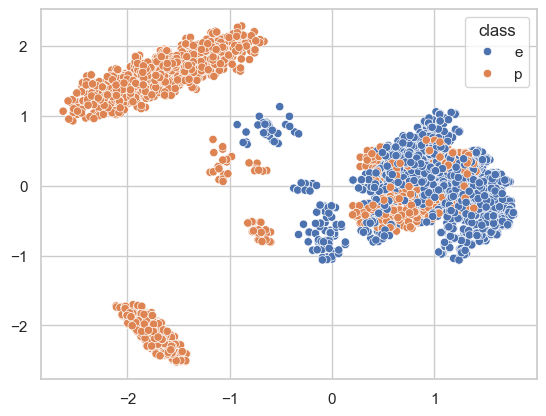

In [14]:
pca = PCA(n_components=2)    # metodo de sklearn
pca.fit(X_train)

X_pca = pca.transform(X_train)

# Representar en un scatterplot y poner en color las etiquetas de entrenamiento
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train)

Parece que está bastante separadito, ¡a ojo mucho se puede ver! :)

Antes de seguir, entrenamos un clasificador supervisado como **línea base** (así sabemos cuánta información hay realmente en los datos).

In [15]:
# 1. Definir el clasificador y el numero de estimadores
rf = RandomForestClassifier(n_estimators=100, random_state=42)
# 2. Entrenar en train
rf.fit(X_train, y_train)
# 3. Calcular la precision sobre test
score = rf.score(X_test, y_test)
print(score)

1.0


Es un conjunto sencillo y Random Forest es muy bueno. Veamos cuántas features tenemos:

In [16]:
X_train.shape

(5443, 115)

¿Muchas features, no? Vamos a reducirlas con PCA y ver cuántas componentes necesita Random Forest para mantener su precisión.

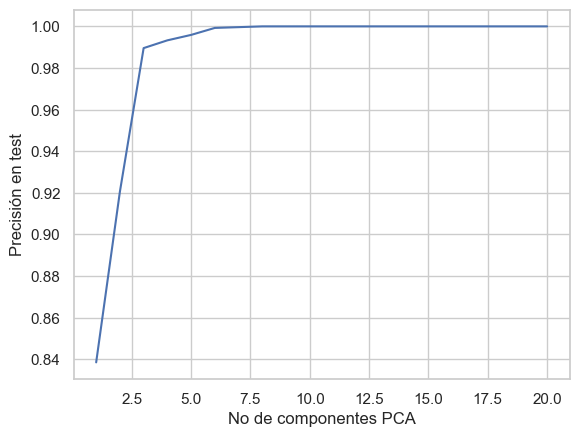

In [18]:
n_features = range(1,21) # definir un rango de valores a probar
scores = []

for n in n_features:
    # 1. Definir y ajustar PCA sobre X_train
    pca = PCA(n_components=n)
    X_train_red = pca.fit_transform(X_train)
    X_test_red = pca.transform(X_test)

    # 2. Entrenar Random Forest sobre los datos reducidos
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_train_red, y_train)
    # 3. Guardar el score en test
    scores.append(rf.score(X_test_red, y_test))

sns.lineplot(x=list(n_features), y=scores)
plt.xlabel('No de componentes PCA')
plt.ylabel('Precisión en test')
plt.show()

A partir de ~10 componentes ya tenemos la precisión que queríamos, reduciendo las variables a una fracción de las originales.

---
## t-SNE: reducción **no lineal** para visualizar

PCA es lineal. **t-SNE** intenta preservar la vecindad local y suele separar mejor los grupos visualmente. Es más caro, así que lo calculamos sobre una **muestra**.

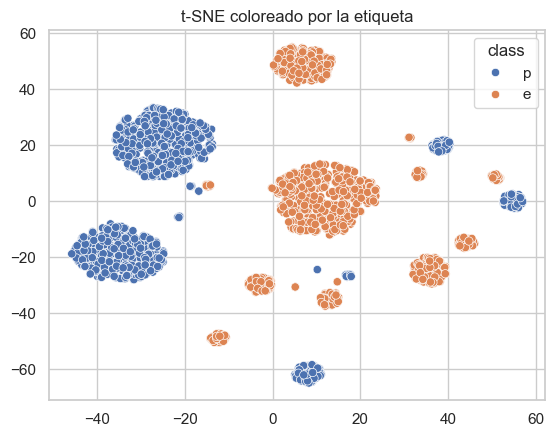

In [20]:
# 1. Tomar una muestra de X_train (t-SNE es lento)
X_sample = X_train.sample(n=2000, random_state=42)
y_sample = y_train.loc[X_sample.index]

# 2. Definir TSNE(n_components=2, ...) y ajustar
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_sample)

# 3. Pintar el embedding coloreado por la etiqueta
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_sample)
plt.title('t-SNE coloreado por la etiqueta')
plt.show()

---
## Clustering

El conjunto es sencillito, así que probemos clustering para ver qué información obtenemos **sin usar las etiquetas**. Trabajaremos sobre una representación reducida con PCA (10 componentes), que limpia ruido y acelera los algoritmos.

In [22]:
# Reducir X (one-hot completo) a 10 componentes con PCA -> X_red
pca10 = PCA(n_components=10, random_state=42)
X_red = pca10.fit_transform(X)
X_red.shape

(8124, 10)

### K-Means: ¿cuántos clusters? Codo + Silhouette

El **método del codo** mira la inercia (suma de distancias a los centroides). El **coeficiente de silhouette** mide cómo de bien separados están los clusters (cuanto más alto, mejor). Usamos ambos.

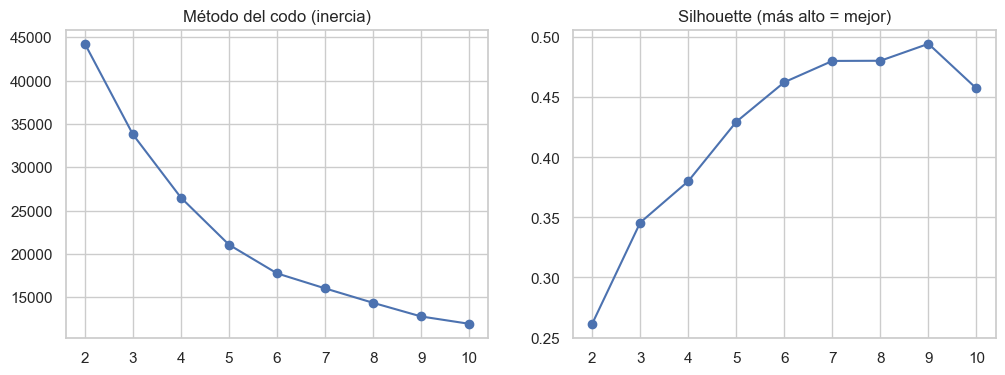

In [23]:
from sklearn.cluster import KMeans

k_values = range(2, 11) # definir un rango
inercias, silhouettes = [], []
for k in k_values:
    # Definir KMeans y ajustar sobre X_red
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_red)
    # Guardar la inercia (km.inertia_) y el silhouette_score
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_red, labels))

# Pintar las dos curvas (codo y silhouette)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inercias, marker='o')
axes[0].set_title('Método del codo (inercia)')
axes[1].plot(list(k_values), silhouettes, marker='o')
axes[1].set_title('Silhouette (más alto = mejor)')
plt.show()

### K-Means final y comparación con la etiqueta

Sabemos que hay dos clases (comestible / venenosa), así que probamos `k=2`. Con `catplot` vemos la distribución de la etiqueta real dentro de cada cluster.

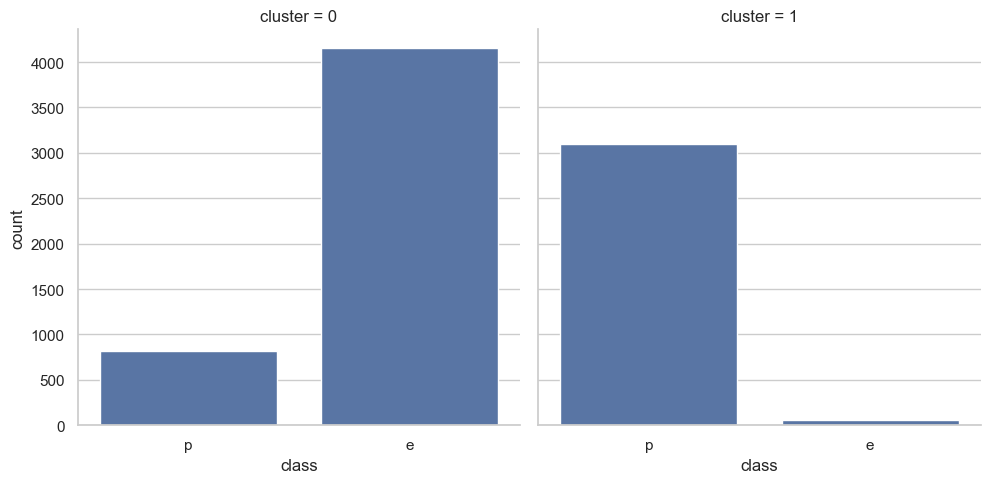

ARI: 0.6170564946596258
NMI 0.566282507939517


In [24]:
# Aprender KMeans con el k obtenido y preparar el catplot.
y_bin = (y == 'p').astype(int)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10) # Definir y entrenar KMeans
clusters = kmeans.fit_predict(X_red)

# ax = sns.catplot(col=, x=, data=, kind='count', col_wrap=4)
df_plot = pd.DataFrame({'cluster': clusters, 'class': y})
sns.catplot(col='cluster', x='class', data=df_plot, kind='count')
plt.show()

# Calcular ARI y NMI frente a y_bin
print('ARI:', adjusted_rand_score(y_bin, clusters))
print('NMI', normalized_mutual_info_score(y_bin, clusters))

> **ARI / NMI** comparan los clusters con la etiqueta real (0 = aleatorio, 1 = idéntico). Sin haber visto la etiqueta, K-Means recupera buena parte de la estructura comestible/venenosa, pero **no es perfecto**: ese es el reto real del no supervisado.

### Comparativa de algoritmos de clustering

Vamos a poner a competir **K-Means, Aglomerativo, GMM y DBSCAN** con varias métricas. Las tres primeras métricas son *internas* (no usan etiqueta); ARI sí la usa, para validar.

In [28]:
# Definir una funcion evaluar(nombre, labels, X) que devuelva silhouette,
# davies_bouldin, calinski_harabasz y ARI.
# Aplicarla a KMeans, AgglomerativeClustering, GaussianMixture y DBSCAN
# y montar una tabla (DataFrame) comparativa.

def evaluar(nombre, labels, X):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters < 2:
        return {'modelo': nombre, 'n_clusters': n_clusters,
                'silhouette': np.nan, 'davies_bouldin': np.nan,
                'calinski_harabasz': np.nan, 'ARI': adjusted_rand_score(y_bin, labels)}
    return{
        'modelo': nombre,
        'n_clusters': n_clusters,
        'silhouette': silhouette_score(X, labels),
        'davies_bouldin': davies_bouldin_score(X, labels),
        'calinski_harabasz': calinski_harabasz_score(X, labels),
        'ARI': adjusted_rand_score(y_bin, labels),
    }


resultados = []
resultados.append(evaluar('KMeans', clusters, X_red))

agg = AgglomerativeClustering(n_clusters=2)
resultados.append(evaluar('Aglomerativo', agg.fit_predict(X_red), X_red))

gmm = GaussianMixture(n_components=2, random_state=42)
resultados.append(evaluar('GMM', gmm.fit_predict(X_red), X_red))

dbscan = DBSCAN(eps=1.5, min_samples=10)
resultados.append(evaluar('DBSCAN', dbscan.fit_predict(X_red), X_red))

pd.DataFrame(resultados)

,modelo,n_clusters,silhouette,davies_bouldin,calinski_harabasz,ARI
0,KMeans,2,0.261416,1.692939,2564.691274,0.617056
1,Aglomerativo,2,0.258872,1.696264,2503.624971,0.608952
2,GMM,2,0.257873,1.700914,2500.017463,0.598621
3,DBSCAN,6,0.357992,1.070795,2304.340409,0.373645


### Dendrograma (clustering jerárquico)

El clustering aglomerativo construye una jerarquía que podemos visualizar como **dendrograma**. La altura a la que se unen dos grupos indica cómo de distintos son. Lo calculamos sobre una muestra para que se lea bien.

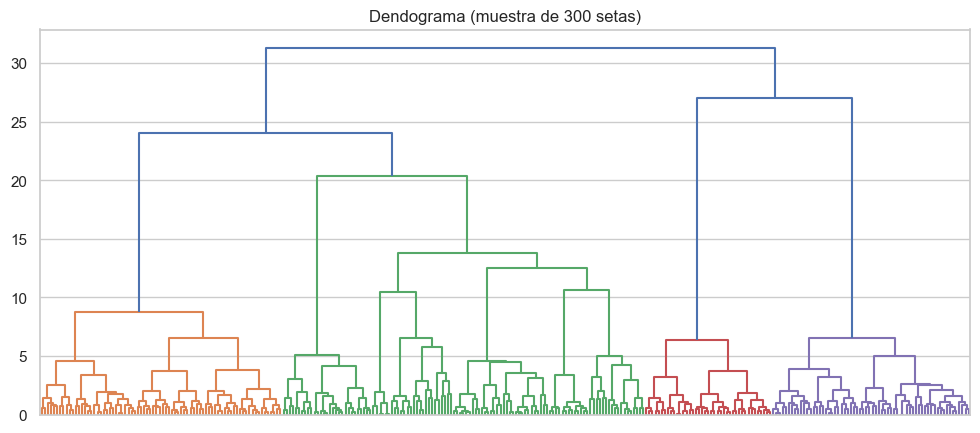

In [29]:
# 1. Tomar una muestra de X_red
# 2. linkage(..., method='ward')
# 3. dendrogram(...) para visualizar la jerarquia

from scipy.cluster.hierarchy import linkage, dendrogram

idx = np.random.RandomState(42).choice(len(X_red), 300, replace=False)
Z = linkage(X_red[idx], method='ward')
plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True)
plt.title('Dendograma (muestra de 300 setas)')
plt.show()


### DBSCAN: la **métrica de distancia importa**

DBSCAN agrupa por densidad. Pero con datos **categóricos** codificados en one-hot, la distancia euclídea no captura bien la similitud. Comparemos euclídea (sobre PCA) con la distancia de **Jaccard** (pensada para datos binarios).

In [30]:
# Comparar DBSCAN con metric='euclidean' (sobre X_red) y metric='jaccard'
# (sobre el one-hot binario). Observar cual recupera mejor la estructura (ARI).

db_eu = DBSCAN(eps=1.5, min_samples=10).fit_predict(X_red)
db_ja = DBSCAN(eps=0.4, min_samples=10, metric='jaccard').fit_predict(X.values.astype(bool))

print('Euclídea -> ARI:', adjusted_rand_score(y_bin, db_eu))
print('Jaccard  -> ARI:', adjusted_rand_score(y_bin, db_ja))

Euclídea -> ARI: 0.37364464459063235
Jaccard  -> ARI: 0.4430440887971433


> **Lección:** con datos categóricos, elegir la distancia adecuada (Jaccard/Hamming) puede cambiar por completo el resultado de un algoritmo basado en densidad. No hay un algoritmo que gane siempre: depende del tipo de datos.

### Visualización final: clusters vs etiqueta real

Repetimos el scatter PCA, pero coloreando por el cluster de K-Means y por la etiqueta real, lado a lado.

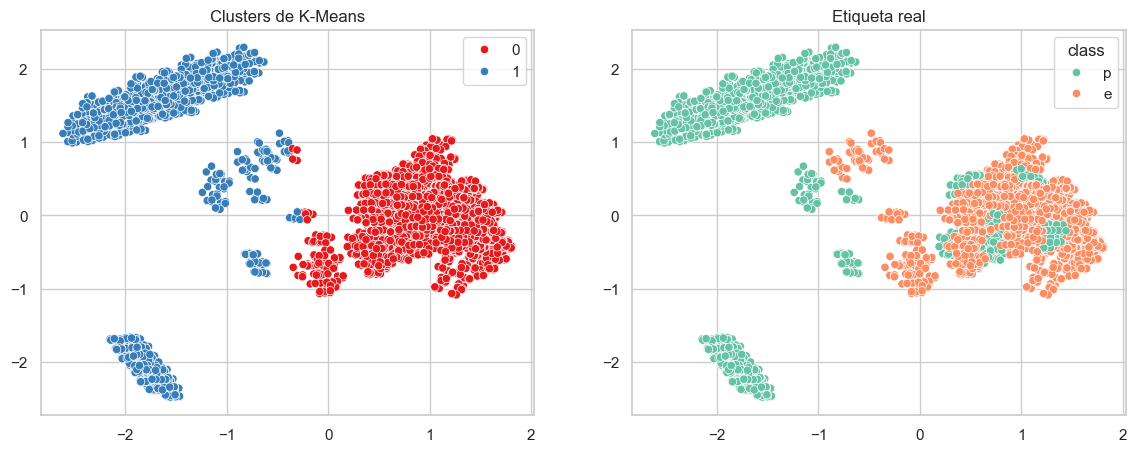

In [31]:
# Entrenar PCA(2) sobre X para representar.
# Pintar dos scatter: uno coloreado por el cluster de KMeans y otro por la etiqueta real.
X_2d = PCA(n_components=2, random_state=42).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=clusters, ax=axes[0], palette='Set1')
axes[0].set_title('Clusters de K-Means')
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y, ax=axes[1], palette='Set2')
axes[1].set_title('Etiqueta real')
plt.show()

Es bastante parecido, ¿no? No es tan bueno como Random Forest (que usa etiquetas), pero K-Means ha identificado bastante bien la estructura **sin usarlas**. Si no tuviéramos etiquetas, esta aproximación nos ayudaría mucho a clasificar los tipos de hongos.

---
## Detección de anomalías (Isolation Forest)

Una tarea no supervisada distinta: encontrar las muestras **atípicas**. Isolation Forest aísla los puntos raros con pocos cortes aleatorios.

Nº de anomalías: 163


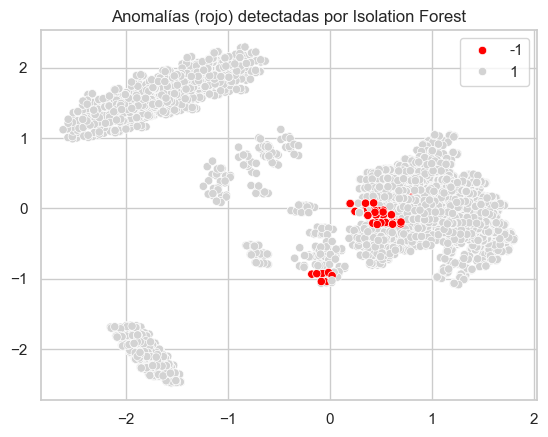

In [32]:
# 1. Definir IsolationForest(contamination=...) y ajustar sobre X_red
# 2. predict -> -1 son anomalias
# 3. Pintarlas sobre la proyeccion PCA
iso = IsolationForest(contamination=0.02, random_state=42)  # suponemos un 2% de setas raras
anomalias = iso.fit_predict(X_red)                          # -1 = rara, 1 = normal
print('Nº de anomalías:', (anomalias == -1).sum())

sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=anomalias, palette={1: 'lightgrey', -1: 'red'})
plt.title('Anomalías (rojo) detectadas por Isolation Forest')
plt.show()

---
## Para ir más allá (opcional)

- **UMAP** (`pip install umap-learn`): alternativa a t-SNE, más rápida y preserva mejor la estructura global.
- **HDBSCAN** (`pip install hdbscan`): DBSCAN jerárquico que no necesita fijar `eps`.
- **Reglas de asociación** (`mlxtend`, Apriori/FP-Growth): muy naturales aquí por ser datos categóricos; permiten descubrir reglas tipo «si olor = X entonces venenosa».

## Conclusiones

- PCA y t-SNE nos dejaron *ver* un dataset de >100 dimensiones.
- K-Means, GMM y Aglomerativo recuperan la estructura comestible/venenosa con ARI ~0.6 **sin usar la etiqueta**.
- DBSCAN nos enseñó que **la métrica de distancia importa** con datos categóricos.
- Isolation Forest localiza las setas más atípicas.
- El no supervisado no da una respuesta «perfecta», pero descubre estructura muy útil cuando no tenemos etiquetas.